# Modelo Preditivo de Pico de Risco Cardíaco

**Objetivo:** gerar uma base sintética, preparar os dados, treinar e avaliar modelos supervisionados de classificação, selecionar o modelo final, salvá-lo e simular a previsão de um novo caso para posterior integração com uma arquitetura multiagente.

> **Aviso de uso:** este notebook é exclusivamente acadêmico. Os dados, limites e protocolos são sintéticos e não possuem validação clínica. A solução não deve ser utilizada para diagnóstico, prescrição ou tomada de decisão médica real.

## 1. Configuração do ambiente

No Google Colab, as bibliotecas principais normalmente já estão instaladas. A célula abaixo importa os pacotes usados e configura a reprodução dos resultados.

In [11]:
import json
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
np.random.seed(42)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print('Ambiente configurado com sucesso.')

Ambiente configurado com sucesso.


## 2. Geração da base sintética

A variável-alvo `pico_risco` é criada a partir da soma de seis condições de risco. O caso é classificado como pico de risco quando pelo menos duas condições são verdadeiras.

In [12]:
SEMENTE = 42
N_AMOSTRAS = 5000
rng = np.random.default_rng(SEMENTE)

# A sequência abaixo preserva a lógica da base fornecida na atividade.
np.random.seed(SEMENTE)
df = pd.DataFrame({
    'idade_media': np.random.normal(55, 12, N_AMOSTRAS).clip(18, 90),
    'carga_sistema': np.random.uniform(30, 100, N_AMOSTRAS),
    'tempo_espera': np.random.normal(45, 20, N_AMOSTRAS).clip(5, 180),
    'fc_media': np.random.normal(85, 15, N_AMOSTRAS).clip(50, 150),
    'spo2_media': np.random.normal(95, 3, N_AMOSTRAS).clip(70, 100),
    'pa_sistolica': np.random.normal(125, 20, N_AMOSTRAS).clip(80, 200),
    'temperatura': np.random.normal(24, 5, N_AMOSTRAS).clip(10, 40),
    'densidade_eventos': np.random.poisson(3, N_AMOSTRAS),
    'eventos_24h': np.random.poisson(2, N_AMOSTRAS),
    'disponibilidade_recursos': np.random.uniform(20, 100, N_AMOSTRAS),
})

risk_score = (
    (df['carga_sistema'] > 80).astype(int)
    + (df['tempo_espera'] > 60).astype(int)
    + (df['spo2_media'] < 92).astype(int)
    + (df['fc_media'] > 110).astype(int)
    + (df['eventos_24h'] > 4).astype(int)
    + (df['disponibilidade_recursos'] < 40).astype(int)
)

df['pico_risco'] = (risk_score >= 2).astype(int)

print(f'Dimensão da base: {df.shape[0]} linhas e {df.shape[1]} colunas')
display(df.head())

Dimensão da base: 5000 linhas e 11 colunas


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


## 3. Validação e análise exploratória

Esta etapa verifica tipos, valores ausentes, duplicidades, estatísticas descritivas e distribuição da classe-alvo.

In [13]:
resumo_qualidade = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'percentual_nulos': (df.isna().mean() * 100).round(2),
    'valores_unicos': df.nunique(),
})

print(f'Linhas duplicadas: {df.duplicated().sum()}')
display(resumo_qualidade)
display(df.describe().T.round(2))

Linhas duplicadas: 0


,tipo,nulos,percentual_nulos,valores_unicos
idade_media,float64,0,0.0,4987
carga_sistema,float64,0,0.0,5000
tempo_espera,float64,0,0.0,4892
fc_media,float64,0,0.0,4946
spo2_media,float64,0,0.0,4763
pa_sistolica,float64,0,0.0,4944
temperatura,float64,0,0.0,4979
densidade_eventos,int32,0,0.0,13
eventos_24h,int32,0,0.0,10
disponibilidade_recursos,float64,0,0.0,5000


,count,mean,std,min,25%,50%,75%,max
idade_media,5000.0,55.06,11.93,18.00,47.11,55.16,62.99,90.00
carga_sistema,5000.0,64.64,19.99,30.00,47.60,64.43,81.68,99.98
tempo_espera,5000.0,45.24,19.38,5.00,31.84,45.14,58.28,113.58
fc_media,5000.0,85.31,14.90,50.00,75.00,85.22,95.60,150.00
spo2_media,5000.0,94.92,2.87,83.43,92.90,94.98,97.01,100.00
pa_sistolica,5000.0,124.89,19.53,80.00,111.20,125.06,138.05,198.83
temperatura,5000.0,24.00,5.08,10.00,20.51,23.97,27.51,40.00
densidade_eventos,5000.0,3.00,1.73,0.00,2.00,3.00,4.00,13.00
eventos_24h,5000.0,1.99,1.42,0.00,1.00,2.00,3.00,9.00
disponibilidade_recursos,5000.0,60.27,23.03,20.04,40.19,60.87,80.39,99.99


,quantidade,percentual
classe,,
0,3671,73.42
1,1329,26.58


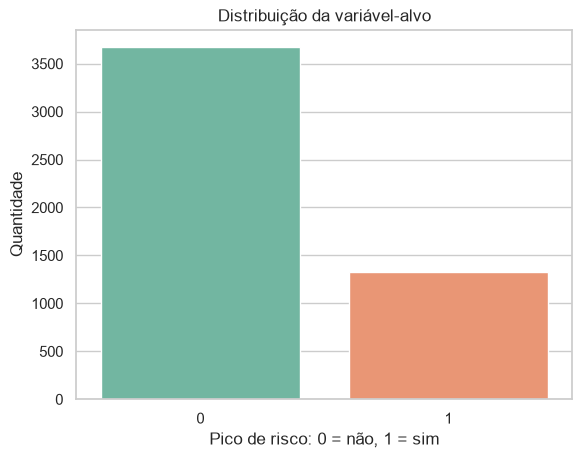

In [14]:
distribuicao = df['pico_risco'].value_counts().sort_index().rename_axis('classe').to_frame('quantidade')
distribuicao['percentual'] = (distribuicao['quantidade'] / len(df) * 100).round(2)
display(distribuicao)

ax = sns.countplot(data=df, x='pico_risco', hue='pico_risco', palette='Set2', legend=False)
ax.set_title('Distribuição da variável-alvo')
ax.set_xlabel('Pico de risco: 0 = não, 1 = sim')
ax.set_ylabel('Quantidade')
plt.show()

### Correlação entre as variáveis

A correlação mostra associações lineares. Ela não representa causalidade e não substitui a avaliação preditiva.

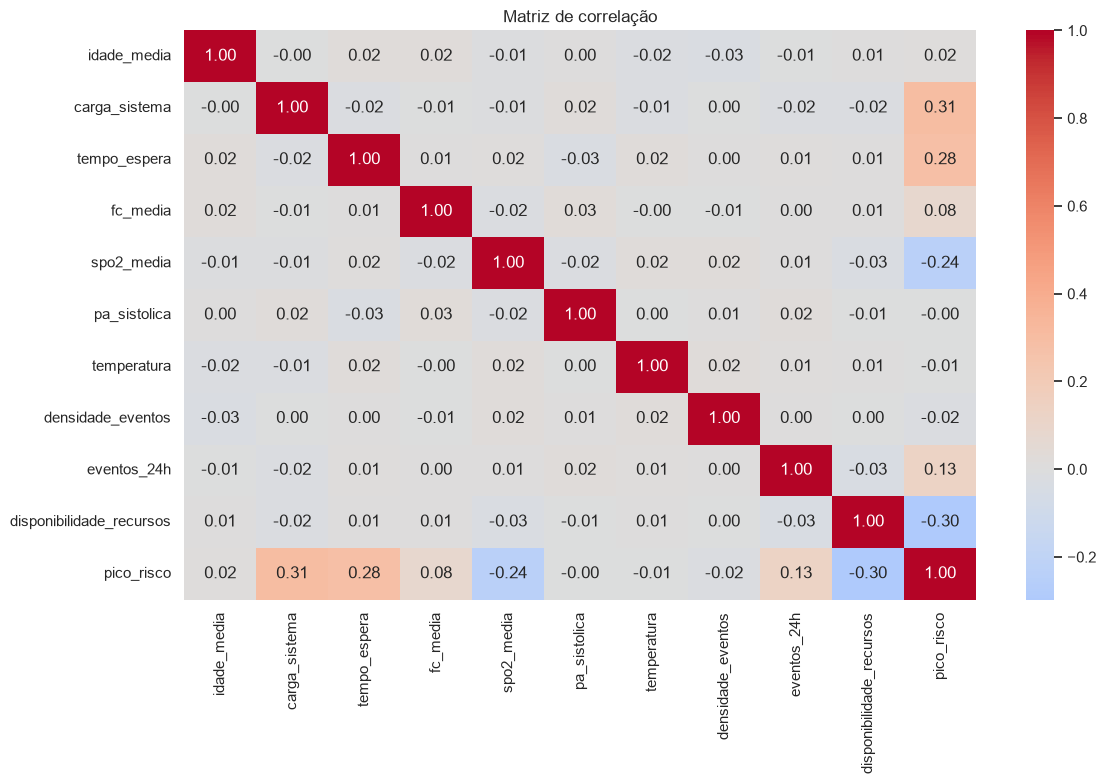

In [15]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação')
plt.tight_layout()
plt.show()

## 4. Preparação dos dados

A divisão utiliza 80% para treino e 20% para teste. O parâmetro `stratify` mantém a proporção das classes e `random_state=42` torna o experimento reproduzível.

In [16]:
COLUNAS_MODELO = [
    'idade_media',
    'carga_sistema',
    'tempo_espera',
    'fc_media',
    'spo2_media',
    'pa_sistolica',
    'temperatura',
    'densidade_eventos',
    'eventos_24h',
    'disponibilidade_recursos',
]

X = df[COLUNAS_MODELO].copy()
y = df['pico_risco'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print('Treino:', X_train.shape, y_train.shape)
print('Teste: ', X_test.shape, y_test.shape)
print('\nProporção da classe 1:')
print(f'Treino: {y_train.mean():.2%}')
print(f'Teste:  {y_test.mean():.2%}')

Treino: (4000, 10) (4000,)
Teste:  (1000, 10) (1000,)

Proporção da classe 1:
Treino: 26.57%
Teste:  26.60%


## 5. Treinamento dos modelos

Serão comparados:

1. **Regressão Logística:** modelo interpretável, adequado para classificação binária e geração de probabilidades.
2. **Random Forest:** modelo não linear capaz de representar melhor os limites usados na geração do alvo.

A seleção será feita principalmente pelo **recall da classe positiva**, usando ROC-AUC e F1-score como critérios complementares. Neste cenário simulado, o recall ajuda a reduzir falsos negativos.

In [17]:
modelos = {
    'Regressão Logística': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=42,
        )),
    ]),
    'Random Forest': Pipeline([
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1,
        )),
    ]),
}

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome} treinado.')

Regressão Logística treinado.
Random Forest treinado.


## 6. Avaliação e comparação

Além da acurácia e matriz de confusão, são apresentadas precisão, recall, F1-score e ROC-AUC. A acurácia isolada pode esconder erros importantes quando as classes são desbalanceadas.

In [18]:
def avaliar_modelo(nome, modelo, X_avaliacao, y_real):
    y_pred = modelo.predict(X_avaliacao)
    y_prob = modelo.predict_proba(X_avaliacao)[:, 1]

    return {
        'modelo': nome,
        'acuracia': accuracy_score(y_real, y_pred),
        'precisao': precision_score(y_real, y_pred, zero_division=0),
        'recall': recall_score(y_real, y_pred, zero_division=0),
        'f1_score': f1_score(y_real, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_real, y_prob),
        'y_pred': y_pred,
        'y_prob': y_prob,
    }

resultados_completos = [
    avaliar_modelo(nome, modelo, X_test, y_test)
    for nome, modelo in modelos.items()
]

comparacao = pd.DataFrame([
    {k: v for k, v in resultado.items() if k not in ['y_pred', 'y_prob']}
    for resultado in resultados_completos
]).set_index('modelo').sort_values(['recall', 'roc_auc', 'f1_score'], ascending=False)

display(comparacao.style.format('{:.4f}'))

,acuracia,precisao,recall,f1_score,roc_auc
modelo,,,,,
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
Regressão Logística,0.7840,0.5687,0.7782,0.6571,0.8717


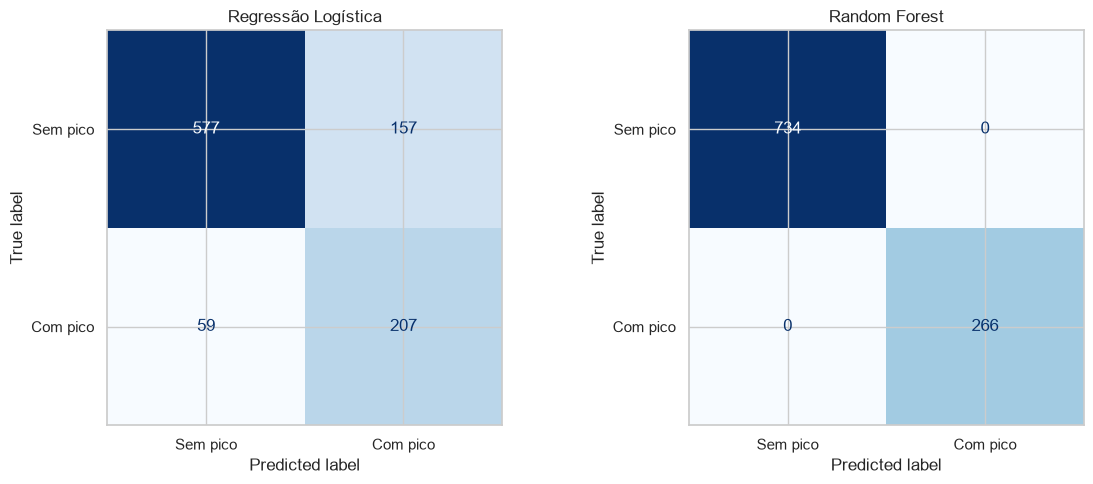

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, resultado in zip(axes, resultados_completos):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        resultado['y_pred'],
        display_labels=['Sem pico', 'Com pico'],
        cmap='Blues',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(resultado['modelo'])

plt.tight_layout()
plt.show()

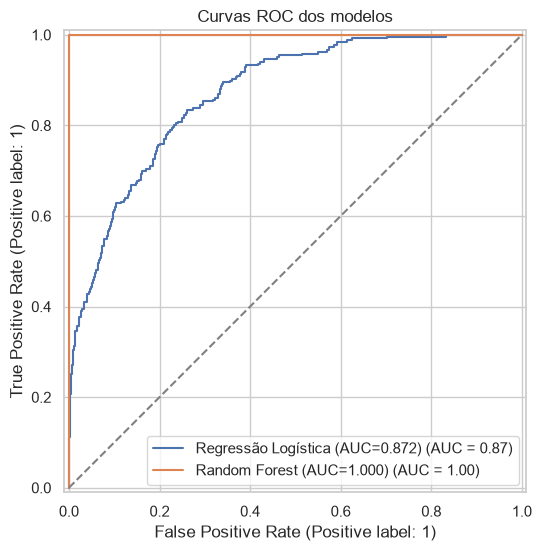

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
for resultado in resultados_completos:
    RocCurveDisplay.from_predictions(
        y_test,
        resultado['y_prob'],
        name=f"{resultado['modelo']} (AUC={resultado['roc_auc']:.3f})",
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_title('Curvas ROC dos modelos')
plt.show()

### Relatórios de classificação

In [21]:
for resultado in resultados_completos:
    print('=' * 70)
    print(resultado['modelo'])
    print('=' * 70)
    print(classification_report(
        y_test,
        resultado['y_pred'],
        target_names=['Sem pico de risco', 'Com pico de risco'],
        digits=4,
    ))

Regressão Logística
                   precision    recall  f1-score   support

Sem pico de risco     0.9072    0.7861    0.8423       734
Com pico de risco     0.5687    0.7782    0.6571       266

         accuracy                         0.7840      1000
        macro avg     0.7380    0.7821    0.7497      1000
     weighted avg     0.8172    0.7840    0.7931      1000

Random Forest
                   precision    recall  f1-score   support

Sem pico de risco     1.0000    1.0000    1.0000       734
Com pico de risco     1.0000    1.0000    1.0000       266

         accuracy                         1.0000      1000
        macro avg     1.0000    1.0000    1.0000      1000
     weighted avg     1.0000    1.0000    1.0000      1000



## 7. Seleção automática do modelo final

O modelo é selecionado pela seguinte ordem de critérios:

1. Maior recall.
2. Maior ROC-AUC.
3. Maior F1-score.

Essa regra deve ser explicada no relatório como uma decisão acadêmica, e não como um critério clínico validado.

In [22]:
nome_modelo_final = comparacao.index[0]
modelo_final = modelos[nome_modelo_final]
resultado_final = next(r for r in resultados_completos if r['modelo'] == nome_modelo_final)

print(f'Modelo selecionado: {nome_modelo_final}')
print(comparacao.loc[nome_modelo_final].round(4))

Modelo selecionado: Random Forest
acuracia    1.0
precisao    1.0
recall      1.0
f1_score    1.0
roc_auc     1.0
Name: Random Forest, dtype: float64


## 8. Interpretação do modelo

A importância por permutação mede quanto o desempenho diminui quando os valores de uma variável são embaralhados. Quanto maior a queda, maior a relevância preditiva da variável para o modelo avaliado.

,variavel,importancia_media,desvio_padrao
9,disponibilidade_recursos,1.347696e-01,5.407860e-03
1,carga_sistema,1.309103e-01,6.270448e-03
2,tempo_espera,1.200493e-01,6.538940e-03
4,spo2_media,9.649720e-02,6.660662e-03
8,eventos_24h,3.682751e-02,1.502226e-03
3,fc_media,2.451497e-02,1.498355e-03
0,idade_media,1.110223e-17,3.330669e-17
6,temperatura,1.110223e-17,3.330669e-17
5,pa_sistolica,0.000000e+00,0.000000e+00
7,densidade_eventos,0.000000e+00,0.000000e+00


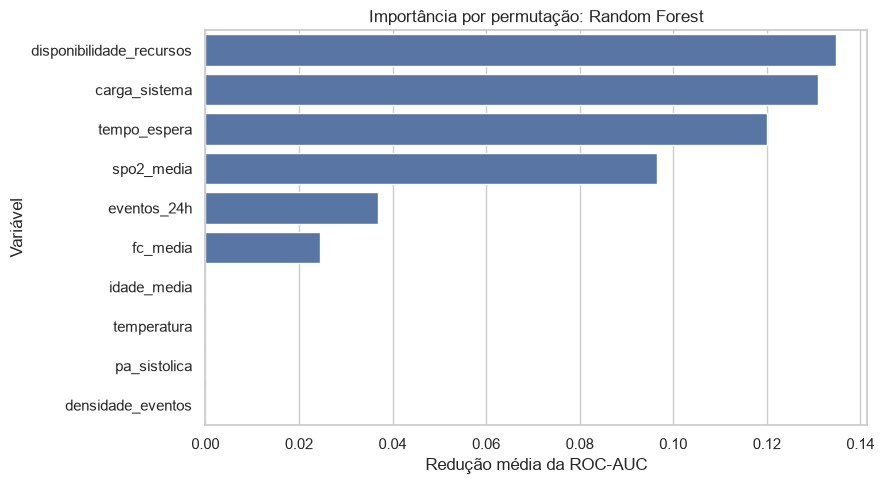

In [23]:
permutacao = permutation_importance(
    modelo_final,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importancias = pd.DataFrame({
    'variavel': COLUNAS_MODELO,
    'importancia_media': permutacao.importances_mean,
    'desvio_padrao': permutacao.importances_std,
}).sort_values('importancia_media', ascending=False)

display(importancias)

plt.figure(figsize=(9, 5))
sns.barplot(data=importancias, x='importancia_media', y='variavel', color='#4C72B0')
plt.title(f'Importância por permutação: {nome_modelo_final}')
plt.xlabel('Redução média da ROC-AUC')
plt.ylabel('Variável')
plt.tight_layout()
plt.show()

## 9. Salvamento dos artefatos

São salvos:

- pipeline completo do modelo;
- lista e ordem das colunas;
- métricas de teste;
- base sintética;
- protocolos simulados.

A pasta `artefatos_modelo` poderá ser incluída no repositório e usada pelo sistema multiagente.

In [24]:
PASTA_ARTEFATOS = Path('artefatos_modelo')
PASTA_ARTEFATOS.mkdir(exist_ok=True)

protocolos = [
    'Se SPO2 < 88% → iniciar suporte respiratório imediato',
    'Se carga do sistema > 85% → abrir unidades temporárias',
    'Se FC > 120 → iniciar monitoramento intensivo',
    'Se eventos_24h > 5 → ativar equipe de resposta rápida',
    'Se disponibilidade_recursos < 30% → redistribuir insumos',
    'Se tempo_espera > 90 min → priorizar triagem emergencial',
    'Se temperatura > 38°C média → iniciar protocolo infeccioso',
    'Se densidade_eventos > 6 → ativar plano de contingência',
    'Se PA sistólica < 90 → iniciar protocolo de choque',
    'Se risco sistêmico alto → ativar estado de emergência',
]

metricas_finais = {
    k: float(v)
    for k, v in comparacao.loc[nome_modelo_final].to_dict().items()
}
metricas_finais['modelo'] = nome_modelo_final
metricas_finais['limiar_classificacao_binaria'] = 0.50

joblib.dump(modelo_final, PASTA_ARTEFATOS / 'modelo_risco_cardiaco.joblib')
joblib.dump(COLUNAS_MODELO, PASTA_ARTEFATOS / 'colunas_modelo.joblib')
df.to_csv(PASTA_ARTEFATOS / 'dados_sinteticos.csv', index=False)

with open(PASTA_ARTEFATOS / 'metricas_modelo.json', 'w', encoding='utf-8') as arquivo:
    json.dump(metricas_finais, arquivo, ensure_ascii=False, indent=2)

with open(PASTA_ARTEFATOS / 'protocolos.json', 'w', encoding='utf-8') as arquivo:
    json.dump(protocolos, arquivo, ensure_ascii=False, indent=2)

print('Artefatos salvos:')
for caminho in sorted(PASTA_ARTEFATOS.iterdir()):
    print('-', caminho)

Artefatos salvos:
- artefatos_modelo\colunas_modelo.joblib
- artefatos_modelo\dados_sinteticos.csv
- artefatos_modelo\metricas_modelo.json
- artefatos_modelo\modelo_risco_cardiaco.joblib
- artefatos_modelo\protocolos.json


## 10. Funções para integração

A função de validação impede colunas ausentes, valores não numéricos e valores nulos. A função de classificação converte a probabilidade em uma faixa acadêmica de risco.

In [25]:
def validar_entrada(dados: pd.DataFrame) -> pd.DataFrame:
    if not isinstance(dados, pd.DataFrame):
        raise TypeError('A entrada deve ser um pandas.DataFrame.')

    ausentes = [coluna for coluna in COLUNAS_MODELO if coluna not in dados.columns]
    if ausentes:
        raise ValueError(f'Colunas obrigatórias ausentes: {ausentes}')

    entrada = dados[COLUNAS_MODELO].copy()

    for coluna in COLUNAS_MODELO:
        entrada[coluna] = pd.to_numeric(entrada[coluna], errors='coerce')

    if entrada.isna().any().any():
        colunas_invalidas = entrada.columns[entrada.isna().any()].tolist()
        raise ValueError(f'Valores ausentes ou não numéricos em: {colunas_invalidas}')

    return entrada


def classificar_faixa(probabilidade: float) -> str:
    if not 0 <= probabilidade <= 1:
        raise ValueError('A probabilidade deve estar entre 0 e 1.')
    if probabilidade < 0.30:
        return 'BAIXO'
    if probabilidade < 0.70:
        return 'MODERADO'
    return 'ALTO'


def prever_novo_caso(dados: pd.DataFrame, modelo=modelo_final) -> dict:
    entrada = validar_entrada(dados)
    probabilidade = float(modelo.predict_proba(entrada)[0, 1])
    classe = int(probabilidade >= 0.50)

    return {
        'probabilidade': round(probabilidade, 4),
        'classe_prevista': classe,
        'classificacao': classificar_faixa(probabilidade),
    }

## 11. Simulação de um novo caso

A coluna foi padronizada como `disponibilidade_recursos`, exatamente como no treinamento.

In [26]:
novo_caso = pd.DataFrame([{
    'idade_media': 62,
    'carga_sistema': 92,
    'tempo_espera': 75,
    'fc_media': 118,
    'spo2_media': 89,
    'pa_sistolica': 100,
    'temperatura': 37.5,
    'densidade_eventos': 7,
    'eventos_24h': 5,
    'disponibilidade_recursos': 25,
}])

display(novo_caso)
resultado_novo_caso = prever_novo_caso(novo_caso)
print(json.dumps(resultado_novo_caso, ensure_ascii=False, indent=2))

,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos
0,62,92,75,118,89,100,37.5,7,5,25


{
  "probabilidade": 0.9867,
  "classe_prevista": 1,
  "classificacao": "ALTO"
}


## 12. Seleção determinística dos protocolos simulados

A seleção abaixo usa exatamente as condições descritas na atividade. Observe que `spo2_media = 89` **não** aciona o protocolo `SPO2 < 88%`.

In [27]:
def selecionar_protocolos(dados: pd.DataFrame, classificacao: str) -> list[str]:
    entrada = validar_entrada(dados)
    caso = entrada.iloc[0]
    selecionados = []

    if caso['spo2_media'] < 88:
        selecionados.append('Se SPO2 < 88% → iniciar suporte respiratório imediato')
    if caso['carga_sistema'] > 85:
        selecionados.append('Se carga do sistema > 85% → abrir unidades temporárias')
    if caso['fc_media'] > 120:
        selecionados.append('Se FC > 120 → iniciar monitoramento intensivo')
    if caso['eventos_24h'] > 5:
        selecionados.append('Se eventos_24h > 5 → ativar equipe de resposta rápida')
    if caso['disponibilidade_recursos'] < 30:
        selecionados.append('Se disponibilidade_recursos < 30% → redistribuir insumos')
    if caso['tempo_espera'] > 90:
        selecionados.append('Se tempo_espera > 90 min → priorizar triagem emergencial')
    if caso['temperatura'] > 38:
        selecionados.append('Se temperatura > 38°C média → iniciar protocolo infeccioso')
    if caso['densidade_eventos'] > 6:
        selecionados.append('Se densidade_eventos > 6 → ativar plano de contingência')
    if caso['pa_sistolica'] < 90:
        selecionados.append('Se PA sistólica < 90 → iniciar protocolo de choque')
    if classificacao == 'ALTO':
        selecionados.append('Se risco sistêmico alto → ativar estado de emergência')

    return selecionados

protocolos_sugeridos = selecionar_protocolos(
    novo_caso,
    resultado_novo_caso['classificacao'],
)

resposta_final = {
    **resultado_novo_caso,
    'protocolos_sugeridos': protocolos_sugeridos,
    'aviso': 'Resultado exclusivamente acadêmico, baseado em dados e protocolos sintéticos.',
}

print(json.dumps(resposta_final, ensure_ascii=False, indent=2))

{
  "probabilidade": 0.9867,
  "classe_prevista": 1,
  "classificacao": "ALTO",
  "protocolos_sugeridos": [
    "Se carga do sistema > 85% → abrir unidades temporárias",
    "Se disponibilidade_recursos < 30% → redistribuir insumos",
    "Se densidade_eventos > 6 → ativar plano de contingência",
    "Se risco sistêmico alto → ativar estado de emergência"
  ],
  "aviso": "Resultado exclusivamente acadêmico, baseado em dados e protocolos sintéticos."
}


## 13. Testes básicos de consistência

Esses testes verificam se a probabilidade está no intervalo correto, se a classe é válida, se as colunas esperadas foram preservadas e se os protocolos objetivos do caso foram acionados.

In [28]:
assert 0 <= resultado_novo_caso['probabilidade'] <= 1
assert resultado_novo_caso['classe_prevista'] in [0, 1]
assert resultado_novo_caso['classificacao'] in ['BAIXO', 'MODERADO', 'ALTO']
assert list(novo_caso[COLUNAS_MODELO].columns) == COLUNAS_MODELO
assert any('abrir unidades temporárias' in p for p in protocolos_sugeridos)
assert any('redistribuir insumos' in p for p in protocolos_sugeridos)
assert any('plano de contingência' in p for p in protocolos_sugeridos)
assert not any('suporte respiratório' in p for p in protocolos_sugeridos)

print('Todos os testes básicos foram concluídos com sucesso.')

Todos os testes básicos foram concluídos com sucesso.


## 14. Download dos artefatos no Google Colab

Execute a célula abaixo no Colab para gerar um arquivo ZIP contendo o modelo, as métricas, a base e os protocolos.

In [29]:
import shutil

arquivo_zip = shutil.make_archive(
    'artefatos_modelo_risco',
    'zip',
    root_dir=PASTA_ARTEFATOS,
)
print(f'Arquivo gerado: {arquivo_zip}')

try:
    from google.colab import files
    files.download(arquivo_zip)
except ImportError:
    print('Fora do Google Colab. O ZIP está disponível no diretório atual.')

Arquivo gerado: c:\Users\Usuario\Documents\Cap 1 - Gestão de Crises com Sistema Preditivo em IA_v3\artefatos_modelo_risco.zip
Fora do Google Colab. O ZIP está disponível no diretório atual.


## 15. Conclusões para o relatório técnico

- A base utilizada contém 5.000 registros sintéticos e não utiliza dados pessoais reais.
- O alvo é determinístico e foi criado por regras definidas no próprio exercício.
- Regressão Logística e Random Forest foram comparadas usando o mesmo conjunto de teste.
- A escolha do modelo considera principalmente o recall da classe positiva e, em seguida, ROC-AUC e F1-score.
- O pipeline completo foi salvo para impedir divergências entre treinamento e inferência.
- O novo caso é processado com validação de estrutura e retorna probabilidade, classe e faixa de risco.
- Os protocolos são selecionados por regras determinísticas, evitando que o componente conversacional invente ações.

### Limitações

- Os dados são sintéticos e os protocolos não foram validados clinicamente.
- O alvo foi gerado por regras, portanto o modelo pode apenas aprender padrões derivados dessas regras.
- Os limites de classificação `0,30` e `0,70` são escolhas acadêmicas.
- Em um cenário real seriam necessárias validação externa, calibração, monitoramento de viés, avaliação por especialistas e governança contínua.